<a href="https://colab.research.google.com/github/ohJeez/Athenna-Path/blob/main/WiFiFallDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("x36mustafa/csi-dataset-esp32")

print("Path to dataset files:", path)

100%|██████████| 97.9M/97.9M [00:06<00:00, 15.5MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/x36mustafa/csi-dataset-esp32/versions/1


In [ ]:
import os

dataset_path = "/root/.cache/kagglehub/datasets/x36mustafa/csi-dataset-esp32/versions/1"

for root, dirs, files in os.walk(dataset_path):
    print(root)
    print("Folders:", dirs)
    print("Files:", len(files))
    print("-"*60)

/root/.cache/kagglehub/datasets/x36mustafa/csi-dataset-esp32/versions/1
Folders: ['nonfall', 'fall']
Files: 0
------------------------------------------------------------
/root/.cache/kagglehub/datasets/x36mustafa/csi-dataset-esp32/versions/1/nonfall
Folders: []
Files: 2280
------------------------------------------------------------
/root/.cache/kagglehub/datasets/x36mustafa/csi-dataset-esp32/versions/1/fall
Folders: []
Files: 2100
------------------------------------------------------------


In [ ]:
import glob

files = glob.glob(dataset_path + "/**/*.h5", recursive=True)

print("Total H5 files:", len(files))
print(files[:5])

Total H5 files: 4380
['/root/.cache/kagglehub/datasets/x36mustafa/csi-dataset-esp32/versions/1/nonfall/7rar_Nonfall_setting_sample_012.h5', '/root/.cache/kagglehub/datasets/x36mustafa/csi-dataset-esp32/versions/1/nonfall/nonfall_walking_sample_0374.h5', '/root/.cache/kagglehub/datasets/x36mustafa/csi-dataset-esp32/versions/1/nonfall/nonfall_sitting_sample_0163.h5', '/root/.cache/kagglehub/datasets/x36mustafa/csi-dataset-esp32/versions/1/nonfall/nonfall_walking_sample_0375.h5', '/root/.cache/kagglehub/datasets/x36mustafa/csi-dataset-esp32/versions/1/nonfall/nonfall_sitting_sample_0085.h5']


In [ ]:
import h5py
import numpy as np

sample = files[0]

with h5py.File(sample, "r") as f:
    print("Keys:", list(f.keys()))

    csi = np.array(f["CSI_amps"])

print(csi.shape)

Keys: ['CSI_amps']
(52, 500, 1)


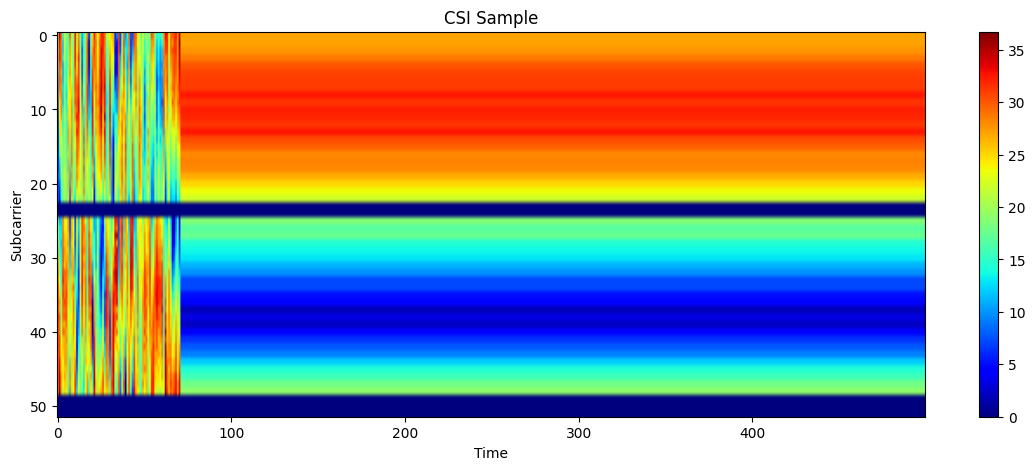

In [ ]:
import matplotlib.pyplot as plt

signal = csi.squeeze()

plt.figure(figsize=(14,5))
plt.imshow(signal,
           aspect="auto",
           cmap="jet")

plt.xlabel("Time")
plt.ylabel("Subcarrier")
plt.title("CSI Sample")
plt.colorbar()
plt.show()

In [ ]:
from collections import Counter

labels = []

for f in files:
    labels.append(os.path.basename(os.path.dirname(f)))

Counter(labels)

Counter({'nonfall': 2280, 'fall': 2100})

In [ ]:
import os
import glob
import h5py
import numpy as np

files = glob.glob(dataset_path + "/fall/*.h5")

print("Total fall samples:", len(files))

sample = files[0]

print(sample)

with h5py.File(sample, "r") as f:
    print("Keys:", list(f.keys()))

    csi = np.array(f["CSI_amps"])

print(csi.shape)

Total fall samples: 2100
/root/.cache/kagglehub/datasets/x36mustafa/csi-dataset-esp32/versions/1/fall/fall_sample_0083.h5
Keys: ['CSI_amps']
(52, 500, 1)


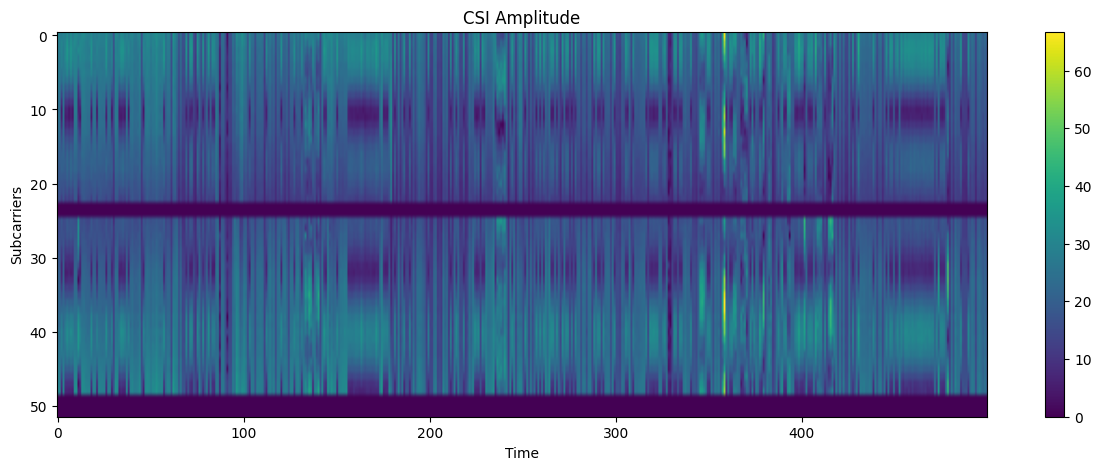

In [ ]:
import matplotlib.pyplot as plt

signal = csi.squeeze()

plt.figure(figsize=(15,5))

plt.imshow(signal,
           aspect='auto',
           cmap='viridis')

plt.xlabel("Time")

plt.ylabel("Subcarriers")

plt.title("CSI Amplitude")

plt.colorbar()

plt.show()

In [ ]:
import numpy as np

def preprocess(csi):
    """
    Preprocess a single CSI sample.

    Input:
        csi shape: (52, 500, 1)

    Output:
        processed shape: (500, 52)
    """

    # Remove last channel dimension
    csi = csi.squeeze(-1)

    # Transpose: subcarriers x time → time x subcarriers
    csi = csi.T

    # Power normalization
    power = np.sum(csi**2, axis=1, keepdims=True)
    csi = csi**2 / (power + 1e-8)

    # Standardize
    csi = (csi - csi.mean()) / (csi.std() + 1e-8)

    return csi

In [ ]:
processed = preprocess(csi)

print("Original shape:", csi.shape)
print("Processed shape:", processed.shape)
print("Mean:", processed.mean())
print("Standard deviation:", processed.std())

Original shape: (52, 500, 1)
Processed shape: (500, 52)
Mean: -2.8170072e-08
Standard deviation: 0.9999992


In [ ]:
import glob
import h5py
import numpy as np

X = []
y = []

classes = {
    "nonfall": 0,
    "fall": 1
}

for cls, label in classes.items():

    folder = os.path.join(dataset_path, cls)

    file_list = glob.glob(folder + "/*.h5")

    print(f"Loading {cls}: {len(file_list)} files")

    for file in file_list:

        with h5py.File(file, "r") as f:
            csi_sample = np.array(f["CSI_amps"])

        processed_sample = preprocess(csi_sample)

        X.append(processed_sample)
        y.append(label)

print("Dataset loading complete!")

Loading nonfall: 2280 files
Loading fall: 2100 files
Dataset loading complete!


In [ ]:
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int64)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4380, 500, 52)
y shape: (4380,)


In [ ]:
from collections import Counter

print(Counter(y))

Counter({np.int64(0): 2280, np.int64(1): 2100})


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

Training samples: (3504, 500, 52)
Testing samples: (876, 500, 52)


In [ ]:
np.save("X_train.npy", X_train)
np.save("X_test.npy", X_test)
np.save("y_train.npy", y_train)
np.save("y_test.npy", y_test)

print("Preprocessed dataset saved successfully!")

Preprocessed dataset saved successfully!


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [ ]:
class CSIDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):

        sample = self.X[index]
        label = self.y[index]

        # Add channel dimension for CNN
        sample = sample.unsqueeze(0)

        return sample, label

In [ ]:
train_dataset = CSIDataset(X_train, y_train)
test_dataset = CSIDataset(X_test, y_test)

print("Train samples:", len(train_dataset))
print("Test samples:", len(test_dataset))

Train samples: 3504
Test samples: 876


In [ ]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [ ]:
for batch_x, batch_y in train_loader:

    print("Input shape:", batch_x.shape)
    print("Labels shape:", batch_y.shape)

    break

Input shape: torch.Size([32, 1, 500, 52])
Labels shape: torch.Size([32])


In [ ]:
sample_x, sample_y = train_dataset[0]

print("Single sample shape:", sample_x.shape)
print("Single label:", sample_y)

Single sample shape: torch.Size([1, 500, 52])
Single label: tensor(1)


# Build the Baseline **CNN**

In [ ]:
import torch.nn as nn

class BaselineCNN(nn.Module):

    def __init__(self):
        super(BaselineCNN, self).__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            # Reduce spatial dimensions
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [ ]:
model = BaselineCNN().to(device)

print(model)

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=32, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(

In [ ]:
total_params = sum(p.numel() for p in model.parameters())

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)

Total Parameters: 25666
Trainable Parameters: 25666


In [ ]:
sample_x, sample_y = next(iter(train_loader))

sample_x = sample_x.to(device)

output = model(sample_x)

print("Input shape:", sample_x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([32, 1, 500, 52])
Output shape: torch.Size([32, 2])


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
def train_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item()

        # Calculate accuracy
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
def evaluate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
epochs = 15

train_losses = []
test_losses = []

train_accuracies = []
test_accuracies = []

for epoch in range(epochs):

    train_loss, train_acc = train_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    test_loss, test_acc = evaluate(
        model,
        test_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    test_losses.append(test_loss)

    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}%"
    )

Epoch [1/15] | Train Loss: 0.3133 | Train Acc: 86.33% | Test Loss: 2.3093 | Test Acc: 52.05%
Epoch [2/15] | Train Loss: 0.2975 | Train Acc: 88.18% | Test Loss: 0.3885 | Test Acc: 81.96%
Epoch [3/15] | Train Loss: 0.2751 | Train Acc: 88.56% | Test Loss: 1.0894 | Test Acc: 63.36%
Epoch [4/15] | Train Loss: 0.2603 | Train Acc: 90.24% | Test Loss: 2.0204 | Test Acc: 51.37%
Epoch [5/15] | Train Loss: 0.2598 | Train Acc: 89.30% | Test Loss: 0.2431 | Test Acc: 90.07%
Epoch [6/15] | Train Loss: 0.2380 | Train Acc: 90.64% | Test Loss: 0.2593 | Test Acc: 88.24%
Epoch [7/15] | Train Loss: 0.2242 | Train Acc: 91.27% | Test Loss: 0.2983 | Test Acc: 86.07%
Epoch [8/15] | Train Loss: 0.2424 | Train Acc: 90.07% | Test Loss: 0.4999 | Test Acc: 79.79%
Epoch [9/15] | Train Loss: 0.2181 | Train Acc: 91.64% | Test Loss: 1.4875 | Test Acc: 54.34%
Epoch [10/15] | Train Loss: 0.2160 | Train Acc: 91.61% | Test Loss: 0.6791 | Test Acc: 71.00%
Epoch [11/15] | Train Loss: 0.2021 | Train Acc: 92.61% | Test Loss: 0

In [ ]:
torch.save(model.state_dict(), "baseline_cnn.pth")

print("Baseline CNN saved successfully!")

Baseline CNN saved successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

model.eval()

y_true = []
y_pred = []
y_probs = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)

        _, predicted = torch.max(outputs, 1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())
        y_probs.extend(probabilities[:, 1].cpu().numpy())

print("Predictions generated successfully!")

Predictions generated successfully!


In [ ]:
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(y_true, y_pred)

recall = recall_score(y_true, y_pred)

f1 = f1_score(y_true, y_pred)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Accuracy : 0.6769
Precision: 0.9928
Recall   : 0.3286
F1 Score : 0.4937


In [ ]:
print(classification_report(
    y_true,
    y_pred,
    target_names=["Non-Fall", "Fall"]
))

              precision    recall  f1-score   support

    Non-Fall       0.62      1.00      0.76       456
        Fall       0.99      0.33      0.49       420

    accuracy                           0.68       876
   macro avg       0.81      0.66      0.63       876
weighted avg       0.80      0.68      0.63       876



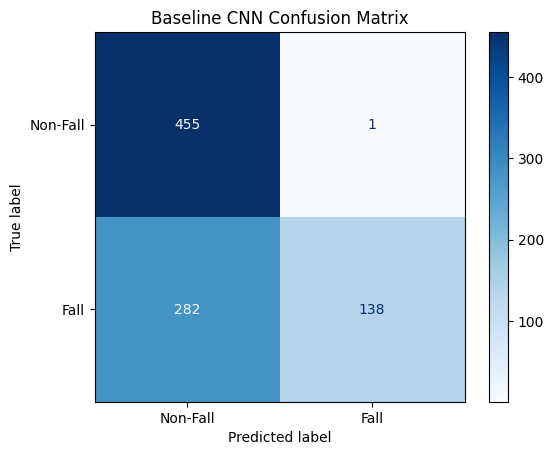

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Fall", "Fall"]
)

disp.plot(cmap="Blues")

plt.title("Baseline CNN Confusion Matrix")
plt.show()

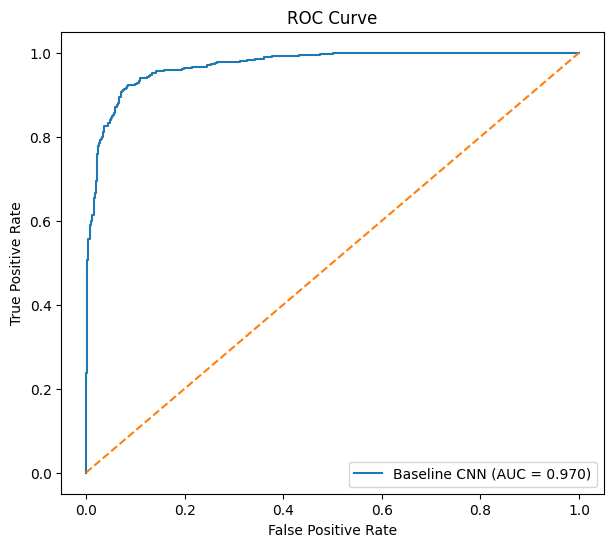

ROC-AUC: 0.9704730576441103


In [ ]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_true, y_probs)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Baseline CNN (AUC = {roc_auc:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print("ROC-AUC:", roc_auc)

In [ ]:
cnn_results = {
    "Model": "Baseline CNN",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "ROC-AUC": roc_auc
}

print(cnn_results)

{'Model': 'Baseline CNN', 'Accuracy': 0.6769406392694064, 'Precision': 0.9928057553956835, 'Recall': 0.32857142857142857, 'F1 Score': 0.4937388193202147, 'ROC-AUC': np.float64(0.9704730576441103)}


In [ ]:
import json

with open("cnn_results.json", "w") as f:
    json.dump(cnn_results, f, indent=4)

print("Results saved!")

Results saved!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

thresholds = np.arange(0.05, 0.96, 0.05)

results = []

for threshold in thresholds:
    preds = (y_probs >= threshold).astype(int)

    tn = np.sum((y_true == 0) & (preds == 0))
    fp = np.sum((y_true == 0) & (preds == 1))
    fn = np.sum((y_true == 1) & (preds == 0))
    tp = np.sum((y_true == 1) & (preds == 1))

    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

for result in results:
    print(result)

{'Threshold': np.float64(0.05), 'Precision': np.float64(0.0), 'Recall': np.float64(0.0), 'F1': np.float64(0.0)}
{'Threshold': np.float64(0.1), 'Precision': np.float64(0.0), 'Recall': np.float64(0.0), 'F1': np.float64(0.0)}
{'Threshold': np.float64(0.15000000000000002), 'Precision': np.float64(0.0), 'Recall': np.float64(0.0), 'F1': np.float64(0.0)}
{'Threshold': np.float64(0.2), 'Precision': np.float64(0.0), 'Recall': np.float64(0.0), 'F1': np.float64(0.0)}
{'Threshold': np.float64(0.25), 'Precision': np.float64(0.0), 'Recall': np.float64(0.0), 'F1': np.float64(0.0)}
{'Threshold': np.float64(0.3), 'Precision': np.float64(0.0), 'Recall': np.float64(0.0), 'F1': np.float64(0.0)}
{'Threshold': np.float64(0.35000000000000003), 'Precision': np.float64(0.0), 'Recall': np.float64(0.0), 'F1': np.float64(0.0)}
{'Threshold': np.float64(0.4), 'Precision': np.float64(0.0), 'Recall': np.float64(0.0), 'F1': np.float64(0.0)}
{'Threshold': np.float64(0.45), 'Precision': np.float64(0.0), 'Recall': np.flo

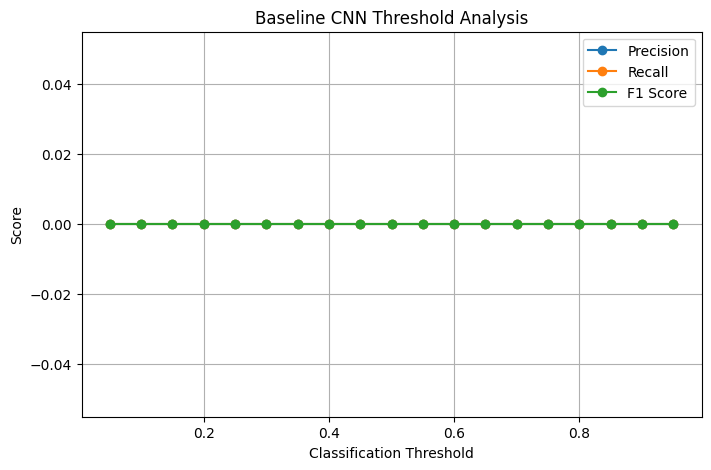

In [ ]:
threshold_values = [r["Threshold"] for r in results]
precision_values = [r["Precision"] for r in results]
recall_values = [r["Recall"] for r in results]
f1_values = [r["F1"] for r in results]

plt.figure(figsize=(8, 5))

plt.plot(threshold_values, precision_values, marker='o', label="Precision")
plt.plot(threshold_values, recall_values, marker='o', label="Recall")
plt.plot(threshold_values, f1_values, marker='o', label="F1 Score")

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Baseline CNN Threshold Analysis")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
best_result = max(results, key=lambda x: x["F1"])

print("Best Threshold:", best_result["Threshold"])
print("Precision:", best_result["Precision"])
print("Recall:", best_result["Recall"])
print("F1 Score:", best_result["F1"])

Best Threshold: 0.05
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [ ]:
target_recall = 0.80

valid_results = [
    r for r in results
    if r["Recall"] >= target_recall
]

if valid_results:
    selected_result = min(valid_results, key=lambda x: x["Threshold"])

    print("Selected Threshold:", selected_result["Threshold"])
    print("Precision:", selected_result["Precision"])
    print("Recall:", selected_result["Recall"])
    print("F1 Score:", selected_result["F1"])
else:
    print("No threshold achieved the target recall.")

No threshold achieved the target recall.


In [ ]:
print("Shape:", np.array(y_probs).shape)
print("Minimum:", np.min(y_probs))
print("Maximum:", np.max(y_probs))
print("First 10 values:", y_probs[:10])

Shape: (876,)
Minimum: 4.92996e-06
Maximum: 0.9985178
First 10 values: [np.float32(0.0024270075), np.float32(0.005145886), np.float32(0.003805785), np.float32(0.0023060774), np.float32(0.08282997), np.float32(7.1261726e-05), np.float32(0.689919), np.float32(0.7019629), np.float32(0.0022343325), np.float32(0.0011191815)]


In [ ]:
import torch
import numpy as np

model.eval()

y_true = []
y_probs = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)

        outputs = model(inputs)

        # Convert logits into probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Probability of class 1 = Fall
        fall_probabilities = probabilities[:, 1]

        y_true.extend(labels.numpy())
        y_probs.extend(fall_probabilities.cpu().numpy())

y_true = np.array(y_true)
y_probs = np.array(y_probs)

print("y_true shape:", y_true.shape)
print("y_probs shape:", y_probs.shape)
print("Minimum probability:", y_probs.min())
print("Maximum probability:", y_probs.max())
print("First 10 Fall probabilities:", y_probs[:10])

y_true shape: (876,)
y_probs shape: (876,)
Minimum probability: 4.92996e-06
Maximum probability: 0.9985178
First 10 Fall probabilities: [2.4270075e-03 5.1458860e-03 3.8057850e-03 2.3060774e-03 8.2829967e-02
 7.1261726e-05 6.8991899e-01 7.0196289e-01 2.2343325e-03 1.1191815e-03]


In [ ]:
predictions_05 = (y_probs >= 0.5).astype(int)

print("Predicted Non-Fall:", np.sum(predictions_05 == 0))
print("Predicted Fall:", np.sum(predictions_05 == 1))

Predicted Non-Fall: 737
Predicted Fall: 139


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.01, 1.00, 0.01)

results = []

for threshold in thresholds:
    preds = (y_probs >= threshold).astype(int)

    precision = precision_score(
        y_true,
        preds,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        preds,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        preds,
        zero_division=0
    )

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

best_result = max(results, key=lambda x: x["F1"])

print("Best Threshold:", best_result["Threshold"])
print("Precision:", best_result["Precision"])
print("Recall:", best_result["Recall"])
print("F1 Score:", best_result["F1"])

Best Threshold: 0.01
Precision: 0.9101654846335697
Recall: 0.9166666666666666
F1 Score: 0.9134045077105575


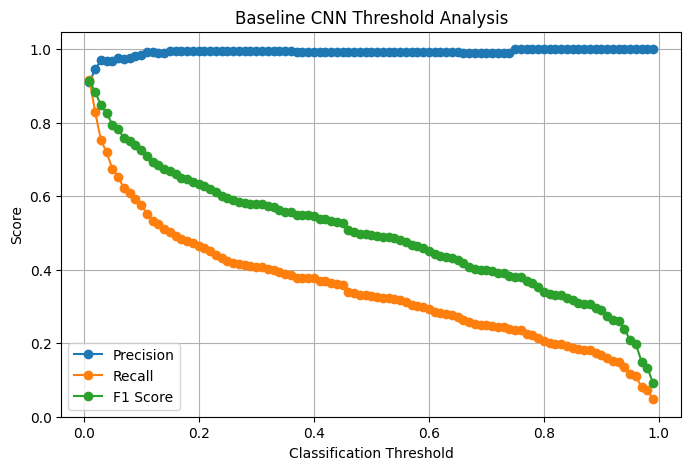

In [ ]:
import matplotlib.pyplot as plt

threshold_values = [r["Threshold"] for r in results]
precision_values = [r["Precision"] for r in results]
recall_values = [r["Recall"] for r in results]
f1_values = [r["F1"] for r in results]

plt.figure(figsize=(8, 5))

plt.plot(
    threshold_values,
    precision_values,
    marker='o',
    label="Precision"
)

plt.plot(
    threshold_values,
    recall_values,
    marker='o',
    label="Recall"
)

plt.plot(
    threshold_values,
    f1_values,
    marker='o',
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Baseline CNN Threshold Analysis")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
best_result = max(results, key=lambda x: x["F1"])

print("Best Threshold:", best_result["Threshold"])
print("Precision:", best_result["Precision"])
print("Recall:", best_result["Recall"])
print("F1 Score:", best_result["F1"])

Best Threshold: 0.01
Precision: 0.9101654846335697
Recall: 0.9166666666666666
F1 Score: 0.9134045077105575


In [ ]:
high_recall_results = [
    r for r in results
    if r["Recall"] >= 0.80
]

if high_recall_results:
    selected_result = max(
        high_recall_results,
        key=lambda x: x["Precision"]
    )

    print("Selected Threshold:", selected_result["Threshold"])
    print("Precision:", selected_result["Precision"])
    print("Recall:", selected_result["Recall"])
    print("F1 Score:", selected_result["F1"])

Selected Threshold: 0.02
Precision: 0.9456521739130435
Recall: 0.8285714285714286
F1 Score: 0.883248730964467


[[418  38]
 [ 35 385]]


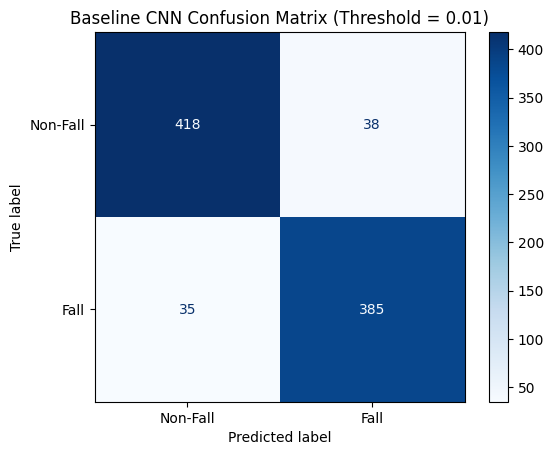

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_threshold = best_result["Threshold"]

optimized_predictions = (
    y_probs >= best_threshold
).astype(int)

cm = confusion_matrix(
    y_true,
    optimized_predictions
)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Fall", "Fall"]
)

disp.plot(cmap="Blues")
plt.title(
    f"Baseline CNN Confusion Matrix "
    f"(Threshold = {best_threshold:.2f})"
)
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def calculate_metrics(y_true, predictions):
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1 Score": f1_score(y_true, predictions, zero_division=0)
    }

default_predictions = (y_probs >= 0.5).astype(int)

default_metrics = calculate_metrics(
    y_true,
    default_predictions
)

optimized_metrics = calculate_metrics(
    y_true,
    optimized_predictions
)

print("Default Threshold (0.5)")
print(default_metrics)

print("\nOptimized Threshold")
print(optimized_metrics)

Default Threshold (0.5)
{'Accuracy': 0.6769406392694064, 'Precision': 0.9928057553956835, 'Recall': 0.32857142857142857, 'F1 Score': 0.4937388193202147}

Optimized Threshold
{'Accuracy': 0.9166666666666666, 'Precision': 0.9101654846335697, 'Recall': 0.9166666666666666, 'F1 Score': 0.9134045077105575}


In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (3066, 500, 52)
Validation: (657, 500, 52)
Test: (657, 500, 52)


In [ ]:
import json

baseline_results = {
    "model": "Baseline CNN",
    "default_threshold": 0.5,
    "optimized_threshold": 0.01,
    "accuracy": 0.9166666667,
    "precision": 0.9101654846,
    "recall": 0.9166666667,
    "f1_score": 0.9134045077,
    "roc_auc": 0.9704730576
}

with open("baseline_cnn_threshold_results.json", "w") as f:
    json.dump(baseline_results, f, indent=4)

print("Results saved successfully.")

Results saved successfully.


In [ ]:
inference_config = {
    "model_name": "Baseline CNN",
    "threshold": 0.01,
    "classes": {
        "0": "Non-Fall",
        "1": "Fall"
    }
}

with open("inference_config.json", "w") as f:
    json.dump(inference_config, f, indent=4)

In [ ]:
class_counts = np.bincount(y_train)

weights = len(y_train) / (2 * class_counts)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

print("Class weights:", class_weights)

Class weights: tensor([0.9605, 1.0429], device='cuda:0')


In [ ]:
model = BaselineCNN().to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
from torch.utils.data import Dataset, DataLoader
import torch

class CSIDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        sample = self.X[index].unsqueeze(0)
        label = self.y[index]
        return sample, label


train_dataset = CSIDataset(X_train, y_train)
val_dataset = CSIDataset(X_val, y_val)
test_dataset = CSIDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 96
Validation batches: 21
Test batches: 21


In [ ]:
import numpy as np
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [ ]:
class_counts = np.bincount(y_train)

weights = len(y_train) / (2 * class_counts)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(device)

print("Class weights:", class_weights)

Class weights: tensor([0.9605, 1.0429], device='cuda:0')


In [ ]:
model = BaselineCNN().to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
import torch


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        total_loss += loss.item() * inputs.size(0)

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy


def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * inputs.size(0)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy

In [ ]:
print(train_one_epoch)
print(evaluate)

<function train_one_epoch at 0x7ea4114ab9c0>
<function evaluate at 0x7ea40f268cc0>


In [ ]:
print(type(model))
print(len(train_loader))
print(len(val_loader))
print(device)

<class '__main__.BaselineCNN'>
96
21
cuda


In [ ]:
EPOCHS = 10

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "weighted_cnn_best.pth"
        )

        print("Best model saved.")

Epoch [1/10] | Train Loss: 0.6045 | Train Acc: 0.6755 | Val Loss: 0.6810 | Val Acc: 0.6073
Best model saved.
Epoch [2/10] | Train Loss: 0.5111 | Train Acc: 0.7378 | Val Loss: 0.6249 | Val Acc: 0.6880
Best model saved.
Epoch [3/10] | Train Loss: 0.4575 | Train Acc: 0.7714 | Val Loss: 0.4251 | Val Acc: 0.7991
Best model saved.
Epoch [4/10] | Train Loss: 0.4042 | Train Acc: 0.8076 | Val Loss: 0.7769 | Val Acc: 0.6164
Epoch [5/10] | Train Loss: 0.3712 | Train Acc: 0.8288 | Val Loss: 0.5583 | Val Acc: 0.7123
Epoch [6/10] | Train Loss: 0.3373 | Train Acc: 0.8558 | Val Loss: 0.3071 | Val Acc: 0.8691
Best model saved.
Epoch [7/10] | Train Loss: 0.3216 | Train Acc: 0.8679 | Val Loss: 0.4507 | Val Acc: 0.7626
Epoch [8/10] | Train Loss: 0.3091 | Train Acc: 0.8624 | Val Loss: 1.3881 | Val Acc: 0.5799
Epoch [9/10] | Train Loss: 0.2833 | Train Acc: 0.8800 | Val Loss: 0.2894 | Val Acc: 0.8828
Best model saved.
Epoch [10/10] | Train Loss: 0.2649 | Train Acc: 0.8888 | Val Loss: 0.9806 | Val Acc: 0.6697

In [ ]:
model.load_state_dict(
    torch.load(
        "weighted_cnn_best.pth",
        map_location=device
    )
)

model.eval()

print("Best Weighted CNN loaded successfully.")


Best Weighted CNN loaded successfully.


In [ ]:
import numpy as np
import torch


def get_probabilities(model, loader, device):
    model.eval()

    y_true = []
    y_probs = []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)

            outputs = model(inputs)

            # Convert logits to probabilities
            probabilities = torch.softmax(outputs, dim=1)

            # Class 1 = Fall
            fall_probabilities = probabilities[:, 1]

            y_true.extend(labels.numpy())
            y_probs.extend(fall_probabilities.cpu().numpy())

    return np.array(y_true), np.array(y_probs)

In [ ]:
model.load_state_dict(
    torch.load(
        "weighted_cnn_best.pth",
        map_location=device
    )
)

model.eval()

print("Best Weighted CNN loaded successfully.")

Best Weighted CNN loaded successfully.


In [ ]:
y_val_true, y_val_probs = get_probabilities(
    model,
    val_loader,
    device
)

print("Validation samples:", len(y_val_true))
print("Probability range:", y_val_probs.min(), y_val_probs.max())

Validation samples: 657
Probability range: 0.0016142644 0.9990656


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.01, 1.00, 0.01)

threshold_results = []

for threshold in thresholds:
    predictions = (y_val_probs >= threshold).astype(int)

    precision = precision_score(
        y_val_true,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_val_true,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_val_true,
        predictions,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

best_threshold_result = max(
    threshold_results,
    key=lambda x: x["F1"]
)

print("Best Validation Threshold:",
      best_threshold_result["Threshold"])

print("Validation Precision:",
      best_threshold_result["Precision"])

print("Validation Recall:",
      best_threshold_result["Recall"])

print("Validation F1 Score:",
      best_threshold_result["F1"])

Best Validation Threshold: 0.26
Validation Precision: 0.9076433121019108
Validation Recall: 0.9047619047619048
Validation F1 Score: 0.9062003179650239


In [ ]:
y_test_true, y_test_probs = get_probabilities(
    model,
    test_loader,
    device
)

best_threshold = best_threshold_result["Threshold"]

y_test_pred = (
    y_test_probs >= best_threshold
).astype(int)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

test_accuracy = accuracy_score(y_test_true, y_test_pred)

test_precision = precision_score(
    y_test_true,
    y_test_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test_true,
    y_test_pred,
    zero_division=0
)

test_f1 = f1_score(
    y_test_true,
    y_test_pred,
    zero_division=0
)

test_auc = roc_auc_score(
    y_test_true,
    y_test_probs
)

print("Weighted CNN Final Test Results")
print("--------------------------------")
print("Threshold:", best_threshold)
print("Accuracy :", test_accuracy)
print("Precision:", test_precision)
print("Recall   :", test_recall)
print("F1 Score :", test_f1)
print("ROC-AUC  :", test_auc)

print("\nClassification Report:")
print(
    classification_report(
        y_test_true,
        y_test_pred,
        target_names=["Non-Fall", "Fall"],
        zero_division=0
    )
)

Weighted CNN Final Test Results
--------------------------------
Threshold: 0.26
Accuracy : 0.8904109589041096
Precision: 0.8605341246290801
Recall   : 0.9206349206349206
F1 Score : 0.8895705521472392
ROC-AUC  : 0.9616912652000371

Classification Report:
              precision    recall  f1-score   support

    Non-Fall       0.92      0.86      0.89       342
        Fall       0.86      0.92      0.89       315

    accuracy                           0.89       657
   macro avg       0.89      0.89      0.89       657
weighted avg       0.89      0.89      0.89       657



In [ ]:
torch.save(model.state_dict(), "weighted_cnn_final.pth")